# Live SerialAnalysis signals
Run the install and setup cells, then use the receive check below to inspect raw serial bytes. Run the live graph cell separately. Each opens the port, so interrupt one before starting the other.


In [7]:
%pip install pyserial matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import sys
import time

# Allow launch from the repository root or the Live folder.
cwd = Path.cwd().resolve()
repo = cwd if (cwd / "SerialAnalysis" / "Live").is_dir() else cwd.parents[1]
if not (repo / "SerialAnalysis" / "Live").is_dir():
    raise RuntimeError("Start Jupyter from the repository root or SerialAnalysis/Live")
sys.path.insert(0, str(repo))

from IPython.display import display
from matplotlib import pyplot as plt
from SerialAnalysis.Live import LiveRecorder
from SerialAnalysis.Live.live_plot import LivePlot

PORT = "COM8"
OUTPUT = repo / "sessions"
DURATION_MIN = 30
WINDOW_S = 5
REFRESH_S = 0.2


In [4]:
# Diagnostic: print incoming binary chunks and decoded frames for 10 seconds.
# Run this cell while the live graph cell is stopped.
from SerialAnalysis.Live.recorder import open_serial
from SerialAnalysis.Live.protocol import Decoder

MONITOR_SECONDS = 10
decoder = Decoder()
port = open_serial(PORT)
start = last_wait = time.monotonic()
received_bytes = received_frames = 0
print(f"Listening on {PORT} at {port.baudrate} baud, DTR={port.dtr}, for {MONITOR_SECONDS} seconds...", flush=True)
try:
    while time.monotonic() - start < MONITOR_SECONDS:
        chunk = port.read(1024)
        if chunk:
            received_bytes += len(chunk)
            print(f"RX {len(chunk)} bytes: {chunk.hex(' ')}", flush=True)
            frames = decoder.feed(chunk)
            received_frames += len(frames)
            for frame in frames:
                print(f"  frame type={frame.type} seq={frame.sequence} "
                      f"board_us={frame.timestamp_us} samples={frame.count}", flush=True)
        elif time.monotonic() - last_wait >= 1:
            print("Waiting for serial bytes...", flush=True)
            last_wait = time.monotonic()
except KeyboardInterrupt:
    print("Receive check interrupted.", flush=True)
finally:
    port.close()
    print(f"Closed {PORT}: {received_bytes} bytes, {received_frames} frames, "
          f"{decoder.bad} bad CRC/length frames.", flush=True)


Listening on COM8 at 115200 baud, DTR=True, for 10 seconds...
RX 182 bytes: a5 5a 01 76 0b 83 73 ff 04 08 20 00 4d 17 42 26 4f 17 40 26 4d 17 45 26 4d 17 43 26 4d 17 39 26 4c 17 46 26 50 17 41 26 4d 17 42 26 87 c6 a5 5a 02 77 0b 43 d7 fe 04 05 1e 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 8e 2a a5 5a 01 78 0b c3 0f 00 05 08 20 00 4e 17 43 26 4f 17 42 26 4b 17 43 26 4e 17 44 26 4d 17 45 26 51 17 42 26 4d 17 43 26 4d 17 44 26 b1 e8 a5 5a 01 79 0b 03 ac 00 05 08 20 00 4d 17 44 26 4f 17 43 26 50 17 43 26 4b 17 43 26 4d 17 3f 26 4d 17 42 26 4c 17 41 26 4d 17 41 26 f9 d7
  frame type=1 seq=2934 board_us=83850115 samples=8
  frame type=2 seq=2935 board_us=83810115 samples=5
  frame type=1 seq=2936 board_us=83890115 samples=8
  frame type=1 seq=2937 board_us=83930115 samples=8
RX 136 bytes: a5 5a 02 7a 0b e3 5d 00 05 05 1e 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 82 f8 a5 5a 01 7b 0b 43 48 01 

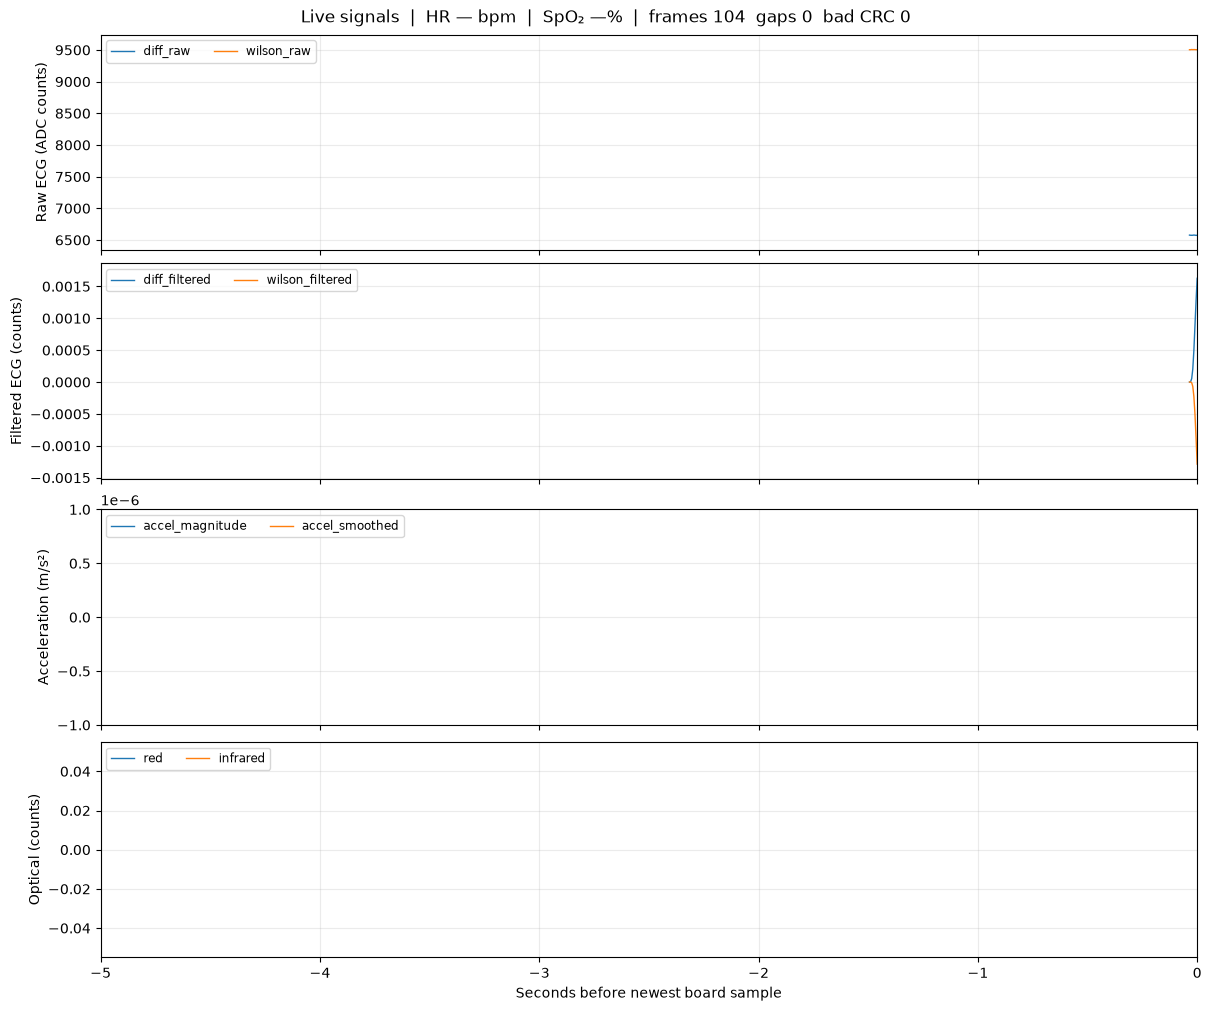

Recording to C:\Users\asher\projects\ece198\sessions\2026-11-19T21-50-32Z; interrupt this cell to stop.
Finished: C:\Users\asher\projects\ece198\sessions\2026-11-19T21-50-32Z


SerialException: ClearCommError failed (PermissionError(13, 'The device does not recognize the command.', None, 22))

In [6]:
with LiveRecorder(PORT, OUTPUT, DURATION_MIN, window_s=WINDOW_S) as recorder:
    plot = LivePlot(WINDOW_S)
    handle = display(plot.figure, display_id=True)
    print(f"Recording to {recorder.session_dir}; interrupt this cell to stop.")
    last_refresh = 0.0
    try:
        while not recorder.done:
            recorder.poll()
            now = time.monotonic()
            if now - last_refresh >= REFRESH_S:
                plot.update(recorder)
                handle.update(plot.figure)
                last_refresh = now
    except KeyboardInterrupt:
        pass
    finally:
        plot.update(recorder)
        handle.update(plot.figure)
        plt.close(plot.figure)
        print(f"Finished: {recorder.session_dir}")
